### **Импорты**

In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier

### **Предобработка данных**

In [6]:
path = "data/credit_risk_dataset.csv"

df = pd.read_csv(path)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [7]:
df.isna().sum()
# person_emp_length
# loan_int_rate

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [8]:
df['person_emp_length'] = df['person_emp_length'].fillna(df['person_emp_length'].mean())
df['loan_int_rate'] = df['loan_int_rate'].fillna(df['loan_int_rate'].mean())

In [9]:
df.head(5)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [10]:
X = df[['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length']]
y = df['loan_status']

#### **Разделение данных**

Исходные данные разделяются на две независимые части: для обучения и оценки production-модели (`X_prod`) и для моделирования дрейфа (`X_sim`).

Данные production-модели дополнительно разделяются на train, validation и test. Данные симуляций позже разделяются на `X_sim_train` и `X_sim_test`, чтобы обеспечить независимую оценку метамодели.

In [11]:
# Разбиение данных для обучения "продовой" модели и для дрифт-данных
X_prod, X_sim, y_prod, y_sim = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Разбиение на обучающую и тестовые выборки
X_train, X_test, y_train, y_test = train_test_split(X_prod, y_prod, test_size=0.2, random_state=42, stratify=y_prod)

In [12]:
# Разбиение обучающей выборки на обучающую и валидационную
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)

In [13]:
print(X_train.shape, X_val.shape, X_test.shape, y_train.shape, y_val.shape, y_test.shape)
print(X_sim.shape, y_sim.shape)

(14661, 11) (4887, 11) (4887, 11) (14661,) (4887,) (4887,)
(8146, 11) (8146,)


In [14]:
cat_features = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

### **Создание и обучение модели**

В качестве production-модели используется CatBoostClassifier для бинарной классификации кредитного дефолта.

Гиперпараметры подбираются по валидационной выборке. Качество оценивается с помощью ROC-AUC и LogLoss. После обучения модель фиксируется и используется во всех экспериментах с дрейфом.

In [15]:
results = []

In [16]:
# l2_leaf_reg_params = [1, 3, 5, 10]

model = CatBoostClassifier(
    depth=4,  # Подобрано
    iterations=2000,
    eval_metric='AUC',
    learning_rate=0.05,  # Подобрано
    loss_function='Logloss',
    verbose=True,
    l2_leaf_reg=1,
    random_strength=1,  # Разбиваем по разным признакам
    random_seed=42,
    early_stopping_rounds=100,
    )

model.fit(X_train, y_train, cat_features=cat_features, eval_set=[(X_val, y_val)], verbose=False)

results.append({
    'best_iteration': model.best_iteration_,
    'train_logloss': model.best_score_['learn']['Logloss'],
    'val_auc': model.best_score_['validation']['AUC'],
    'val_logloss': model.best_score_['validation']['Logloss'],
})

print(results[-1:])

[{'best_iteration': 971, 'train_logloss': 0.15567052770839376, 'val_auc': 0.9312616708394854, 'val_logloss': 0.2024177068571717}]


In [17]:
from sklearn.metrics import roc_auc_score

y_test_proba = model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, y_test_proba)

print("Test AUC:", test_auc)

Test AUC: 0.9385905774987935


### **Drift-data и bootstrap выборки**

In [18]:
X_sim_train, X_sim_test, y_sim_train, y_sim_test = train_test_split(X_sim, y_sim, test_size=0.2, random_state=42, stratify=y_sim)

In [19]:
print(X_sim_train.shape, X_sim_test.shape, y_sim_train.shape, y_sim_test.shape)

(6516, 11) (1630, 11) (6516,) (1630,)


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           32581 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               32581 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


### **Генерация синтетического data drift**

Реализованы 8 типов дрейфа: population shift, missing shift, noise shift, mean shift, variance shift, categorical shift, missing + noise и combined shift.

Для каждого типа предусмотрены три уровня интенсивности: low, average и high. Изменения вносятся в признаки объектов либо в их распределение посредством взвешенного resampling.

При изменении состава выборки соответствующие целевые значения сохраняются вместе с объектами.

In [21]:
from sklearn.utils import resample

def increase_loan_income(X_sim, y_sim, intensity='average', random_state=None):
    """
    Увеличивает значение loan_percent_income
    :param sim_df: Ширина прямоугольника в сантиметрах.
    :keyword str intensity: интенсивность. Может быть 'low', 'average' или 'high'
    :keyword random_state: seed
    :return: weight - веса того, насколько увеличиться процент объектов с loan_income >= 0.75
    """
    intensity_weights = {
        'low': 1.5,
        'average': 2.25,
        'high': 3.0,
    }

    if intensity not in intensity_weights:
        raise ValueError("intensity must be 'low', 'average' or 'high'")

    value = intensity_weights[intensity]

    treshold = X_sim["loan_percent_income"].quantile(0.75)

    weights = np.where(X_sim["loan_percent_income"] >= treshold, value, 1.0)

    X_drift, y_drift = resample(
        X_sim,
        y_sim,
        replace=True,
        n_samples=len(X_sim),
        sample_weight=weights,
        random_state=random_state,
    )

    return X_drift, y_drift

def add_missing_drift(X_sim, y_sim, column='person_emp_length', intensity='average', random_state=None):
    """
    Искусственно увеличивает число пропусков в указанном признаке
    :param X_sim: признаки
    :param y_sim: таргет
    :keyword str column: признак, который хотим увеличить
    :keyword intensity: интенсивность. Может быть 'low', 'average' или 'high'
    :keyword random_state: seed
    :return: X_drift, y_drift
    """

    rates = {
        'low': 0.05,
        'average': 0.15,
        'high': 0.3,
    }

    if intensity not in rates:
        raise ValueError("intensity must be 'low', 'average' or 'high'")

    rng = np.random.default_rng(random_state)

    X_drift, y_drift = X_sim.copy(), y_sim.copy()

    missing_rate = rates[intensity]

    mask = rng.random(len(X_drift)) < missing_rate

    X_drift.loc[mask, column] = np.nan

    return X_drift, y_drift

def add_noise_drift(X_sim, y_sim, column, intensity='average', random_state=None):
    """
    Искусственно добавляет шум в признак
    :param X_sim: признаки
    :param y_sim: таргет
    :param str column: признак, который хотим изменить
    :keyword intensity: интенсивность. Может быть 'low', 'average' или 'high'
    :keyword random_state: seed
    :return: X_drift, y_drift
    """
    rates = {
        'low': 0.05,
        'average': 0.1,
        'high': 0.2,
    }

    if intensity not in rates:
        raise ValueError("intensity must be 'low', 'average' or 'high'")

    rng = np.random.default_rng(random_state)

    X_drift, y_drift = X_sim.copy(), y_sim.copy()

    noise_level = rates[intensity]
    sigma = X_drift[column].std() * noise_level

    noise = rng.normal(loc=0, scale=sigma, size=len(X_drift))

    X_drift[column] = X_drift[column] + noise

    return X_drift, y_drift



def add_numeric_shift(X_sim, y_sim, column, intensity='average', shift_type='mean', min_value=None, random_state=None):
    """
    Сдвигает среднее или разброс числового признака
    :param X_sim: признаки
    :param y_sim: таргет
    :param str column: признак, который хотим увеличить
    :keyword intensity: интенсивность. Может быть 'low', 'average' или 'high'
    :keyword shift_type: тип числового дрейфа. Может быть 'mean' или 'variance'
    :keyword random_state: seed
    :return: X_drift, y_drift
    """
    levels = {
        'low': 0.25,
        'average': 0.5,
        'high': 1,
    }

    if intensity not in levels:
        raise ValueError("intensity must be 'low', 'average' or 'high'")

    if shift_type not in ['mean', 'variance']:
        raise ValueError(f"shift_type must be 'mean' or 'variance'")

    X_drift, y_drift = X_sim.copy(), y_sim.copy()

    strength = levels[intensity]

    mean = X_drift[column].mean()
    std = X_drift[column].std()

    if shift_type == 'mean':
        X_drift[column] = X_drift[column] + std * strength
    elif shift_type == 'variance':
        X_drift[column] = (mean + (X_drift[column] - mean) * (1 + strength))

    if min_value is not None:
        X_drift[column] = X_drift[column].clip(lower=min_value)

    return X_drift, y_drift


def categorical_frequency_shift(X_sim, y_sim, column, category, intensity='average', random_state=None):
    """
    Меняет частоту одной категории, не переписывая значения конкретных клиентов
    :param X_sim: признаки
    :param y_sim: таргет
    :param column: признак, который хотим увеличить
    :param category: тип числового дрейфа. Может быть 'mean' или 'variance'
    :keyword intensity: интенсивность. Может быть 'low', 'average' или 'high'
    :keyword random_state: seed
    :return: X_drift, y_drift
    """
    levels = {
        'low': 1.5,
        'average': 2.25,
        'high': 3,
    }

    if intensity not in levels:
        raise ValueError("intensity must be 'low', 'average' or 'high'")

    if category not in X_sim[column].unique():
        raise ValueError(f"category {category} not found in {column}")

    value = levels[intensity]

    weights = np.where(X_sim[column] == category, value, 1.0)

    X_drift, y_drift = resample(
        X_sim,
        y_sim,
        replace=True,
        n_samples=len(X_sim),
        sample_weight=weights,
        random_state=random_state,
    )

    return X_drift, y_drift


#### **Содание сценариев для разных итоговых drift-выборок**

In [22]:
scenarious = [
    {'name': 'population_shift', 'steps': [(increase_loan_income, {'intensity': 'average'})]},
    {'name': 'missing_shift', 'steps': [(add_missing_drift, {'column': 'person_emp_length', 'intensity': 'average'})]},
    {'name': 'noise_shift', 'steps': [(add_noise_drift, {'column': 'person_income', 'intensity': 'average'})]},
    {'name': 'mean_shift', 'steps': [(add_numeric_shift, {'column': 'person_income', 'shift_type': 'mean', 'intensity': 'average'})]},
    {'name': 'variance_shift', 'steps': [(add_numeric_shift, {'column': 'person_income', 'shift_type': 'variance', 'intensity': 'average', 'min_value': 0})]},
    {'name': 'categorical_shift', 'steps': [(categorical_frequency_shift, {'column': 'person_home_ownership', 'category': 'RENT', 'intensity': 'average'})]},
    {'name': 'missing_noise', 'steps': [(add_missing_drift, {'column': 'person_emp_length', 'intensity': 'average'}), (add_noise_drift, {'column': 'person_income', 'intensity': 'average'})]},
    {'name': 'combined_shift', 'steps': [(increase_loan_income, {'intensity': 'average'}), (add_numeric_shift, {'column': 'person_income', 'shift_type': 'mean', 'intensity': 'average'}), (categorical_frequency_shift, {'column': 'person_home_ownership', 'category': 'RENT', 'intensity': 'average'})]}
]

### Формирование мета-признаков

Для каждого drift-сценария рассчитываются статистические характеристики изменения распределений признаков, включая KS-статистику, расстояние Васерштейна, изменение средних значений, стандартных отклонений и доли пропусков.

Дополнительно оценивается изменение распределения вероятностей, предсказанных production-моделью.

Фактический ΔROC-AUC рассчитывается с использованием целевых значений, но сами мета-признаки от них не зависят.

In [23]:
%pip install scipy

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
Note: you may need to restart the kernel to use updated packages.


In [24]:
from scipy.stats import ks_2samp, wasserstein_distance, yulesimon
from scipy.stats import wasserstein_distance

In [25]:
def get_model_metrics(X_data, y_data, model):
    """Считает и возвращает метрики модели"""
    pred = model.predict_proba(X_data)[:, 1]

    auc = roc_auc_score(y_data, pred)
    pred_mean = pred.mean()
    pred_std = pred.std()

    return {
        'auc': auc,
        'pred_mean': pred_mean,
        'pred_std': pred_std,
    }

In [26]:
def calculate_meta_features(X_base, y_base, X_drift, y_drift, model):
    """
    :param X_base: признаки для предсказания до data-drift
    :param y_base: target до data-drift
    :param X_drift: признаки для предсказания после data-drift
    :param y_drift: target после data-drift
    :param model: модель, которая делает предсказания
    :return: словарь мета-признаков одного drift-сценария
    """
    before = get_model_metrics(X_base, y_base, model)
    after = get_model_metrics(X_drift, y_drift, model)

    auc_base = before["auc"]
    auc_drift = after["auc"]
    delta_auc = auc_drift - auc_base

    delta_mean_income = X_drift["person_income"].mean() - X_base["person_income"].mean()
    delta_std_income = X_drift["person_income"].std() - X_base["person_income"].std()

    delta_pred_mean = after["pred_mean"] - before["pred_mean"]
    delta_pred_std = after["pred_std"] - before["pred_std"]
    delta_missing_emp_length = (X_drift["person_emp_length"].isna().mean() - X_base["person_emp_length"].isna().mean())

    ks_income = ks_2samp(X_base["person_income"].dropna(), X_drift["person_income"].dropna()).statistic
    wasserstein_income = wasserstein_distance(X_base["person_income"].dropna(), X_drift["person_income"].dropna())

    # population shift по loan_percent_income
    ks_loan_percent_income = ks_2samp(
        X_base["loan_percent_income"].dropna(), X_drift["loan_percent_income"].dropna()).statistic
    # categorical shift RENT
    delta_rent_share = ((X_drift["person_home_ownership"] == "RENT").mean() - (X_base["person_home_ownership"] == "RENT").mean())

    return {
    "delta_mean_income": delta_mean_income,
    "delta_std_income": delta_std_income,
    "ks_income": ks_income,
    "wasserstein_income": wasserstein_income,
    "delta_pred_mean": delta_pred_mean,
    "delta_pred_std": delta_pred_std,
    "delta_missing_emp_length": delta_missing_emp_length,
    "auc_base": auc_base,
    "auc_drift": auc_drift,
    "delta_auc": delta_auc,
    "ks_loan_percent_income": ks_loan_percent_income,
    "delta_rent_share": delta_rent_share,
    }

### **Создание выборки для обучения мета-модели**

На основе `X_sim_train` создаются 100 bootstrap-выборок по 1500 объектов. К каждой применяются 8 типов дрейфа с тремя уровнями интенсивности.

Всего формируется 2400 синтетических сценариев. Для каждого сохраняются мета-признаки, фактический ΔROC-AUC и служебная информация о типе дрейфа, интенсивности и bootstrap-группе.

In [27]:
results = []

intensities = ["low", "average", "high"]

for bootstrap_id in range(100):
    X_base, y_base = resample(
        X_sim_train,
        y_sim_train,
        n_samples=1500,
        replace=True,
        random_state=bootstrap_id
    )

    for scenario_id, scenario in enumerate(scenarious):
        for intensity in intensities:
            X_current, y_current = X_base, y_base

            for step_id, (drift_function, params) in enumerate(scenario["steps"]):
                seed = bootstrap_id * 1000 + scenario_id * 100 + step_id

                current_params = params.copy()
                current_params["random_state"] = seed
                current_params["intensity"] = intensity

                X_current, y_current = drift_function(X_current, y_current, **current_params)

            metrics = calculate_meta_features(X_base, y_base, X_current, y_current, model)
            metrics["scenario"] = scenario["name"]
            metrics["bootstrap_id"] = bootstrap_id
            metrics["intensity"] = intensity

            results.append(metrics)

In [28]:
df_meta = pd.DataFrame(results)

df_meta.info()
df_meta.tail(5)

<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   delta_mean_income         2400 non-null   float64
 1   delta_std_income          2400 non-null   float64
 2   ks_income                 2400 non-null   float64
 3   wasserstein_income        2400 non-null   float64
 4   delta_pred_mean           2400 non-null   float64
 5   delta_pred_std            2400 non-null   float64
 6   delta_missing_emp_length  2400 non-null   float64
 7   auc_base                  2400 non-null   float64
 8   auc_drift                 2400 non-null   float64
 9   delta_auc                 2400 non-null   float64
 10  ks_loan_percent_income    2400 non-null   float64
 11  delta_rent_share          2400 non-null   float64
 12  scenario                  2400 non-null   str    
 13  bootstrap_id              2400 non-null   int64  
 14  intensity          

,delta_mean_income,delta_std_income,ks_income,wasserstein_income,delta_pred_mean,delta_pred_std,delta_missing_emp_length,auc_base,auc_drift,delta_auc,ks_loan_percent_income,delta_rent_share,scenario,bootstrap_id,intensity
2395,-82.255201,250.271220,0.022000,739.035969,0.013561,0.007877,0.160000,0.942293,0.912112,-0.030181,0.000000,0.000000,missing_noise,99,average
2396,-164.510402,902.081920,0.032667,1219.279880,0.023696,0.016164,0.302667,0.942293,0.907819,-0.034474,0.000000,0.000000,missing_noise,99,high
2397,7150.438789,-4416.843247,0.166667,8002.195492,0.012286,0.010747,0.000000,0.942293,0.913582,-0.028711,0.070667,0.104000,combined_shift,99,low
2398,12127.323635,-5889.223019,0.241333,13061.066531,0.065283,0.057991,0.000000,0.942293,0.892436,-0.049857,0.209333,0.189333,combined_shift,99,average
2399,28619.867958,-6620.938118,0.512667,29240.925394,0.089249,0.078930,0.000000,0.942293,0.922972,-0.019320,0.265333,0.258667,combined_shift,99,high


In [29]:
df_meta["delta_auc"].describe()
df_meta.groupby(
    ["scenario", "intensity"]
)["delta_auc"].agg(["mean", "std"])

mean       std
scenario          intensity                    
categorical_shift average    0.007227  0.007201
                  high       0.007458  0.007624
                  low        0.002603  0.007902
combined_shift    average   -0.017837  0.015863
                  high      -0.013161  0.012883
                  low       -0.024737  0.013961
mean_shift        average   -0.045005  0.009747
                  high      -0.053048  0.010106
                  low       -0.038766  0.009453
missing_noise     average   -0.027968  0.005711
                  high      -0.038233  0.006373
                  low       -0.021177  0.005336
missing_shift     average   -0.001206  0.000831
                  high      -0.002403  0.001169
                  low       -0.000368  0.000457
noise_shift       average   -0.027091  0.006302
                  high      -0.037178  0.007838
                  low       -0.021229  0.005205
population_shift  average    0.012486  0.008054
                  high       0.015683  0.007010
                  low        0.005918  0.007029
variance_shift    average   -0.038270  0.004910
                  high      -0.055797  0.006447
                  low       -0.035556  0.004975

#### **Подготовка данных для мета-модели**

In [30]:
groups = df_meta['bootstrap_id']

y_meta = df_meta['delta_auc']
X_meta = df_meta.drop(columns=[
    "auc_base",
    "auc_drift",
    "delta_auc",
    "scenario",
    "bootstrap_id",
    "intensity"
])

print(X_meta.info())
print('=================')
print(y_meta.info())

<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   delta_mean_income         2400 non-null   float64
 1   delta_std_income          2400 non-null   float64
 2   ks_income                 2400 non-null   float64
 3   wasserstein_income        2400 non-null   float64
 4   delta_pred_mean           2400 non-null   float64
 5   delta_pred_std            2400 non-null   float64
 6   delta_missing_emp_length  2400 non-null   float64
 7   ks_loan_percent_income    2400 non-null   float64
 8   delta_rent_share          2400 non-null   float64
dtypes: float64(9)
memory usage: 168.9 KB
None
<class 'pandas.Series'>
RangeIndex: 2400 entries, 0 to 2399
Series name: delta_auc
Non-Null Count  Dtype  
--------------  -----  
2400 non-null   float64
dtypes: float64(1)
memory usage: 18.9 KB
None


### **Кросс-валидация метамоделей**

Для обучения используются 9 числовых мета-признаков. Целевой переменной выступает фактическое изменение ROC-AUC.

Оценка проводится с помощью GroupKFold на пяти разбиениях с группировкой по `bootstrap_id`. Это исключает попадание сценариев из одной bootstrap-выборки одновременно в обучающую и валидационную части.

Основные метрики оценки: MAE, RMSE и R².

In [31]:
from sklearn.model_selection import GroupKFold

cv = GroupKFold(n_splits=5)

In [34]:
for train_idx, val_idx in cv.split(X_meta, y_meta, groups=groups):
    X_train = X_meta.iloc[train_idx]
    X_val = X_meta.iloc[val_idx]

    y_train = y_meta.iloc[train_idx]
    y_val = y_meta.iloc[val_idx]

    train_groups = set(groups.iloc[train_idx])
    val_groups = set(groups.iloc[val_idx])

    print(train_groups & val_groups)

set()
set()
set()
set()
set()


### **Обучение метамоделей**

#### **meta Линейная регрессия**

In [38]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

meta_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1),
)

In [39]:
from sklearn.model_selection import cross_validate

scores = cross_validate(
    meta_model,
    X_meta,
    y_meta,
    groups=groups,
    cv=cv,
    scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2']
)

In [51]:
print("Linear regression metrics")
print("MAE:", -scores["test_neg_mean_absolute_error"].mean())
print("RMSE:", -scores["test_neg_root_mean_squared_error"].mean())
print("R2:", scores["test_r2"].mean())

Linear regression metrics
MAE: 0.00927540623433826
RMSE: 0.01178723024205687
R2: 0.7279254567480014


In [41]:
meta_model.fit(X_meta, y_meta)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['delta_mean_income','delta_std_income','ks_income',..., 'delta_missing_emp_length','ks_loan_percent_income','delta_rent_share']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


#### **meta RandomForest**

In [42]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

In [43]:
rf_scores = cross_validate(
    rf_model,
    X_meta,
    y_meta,
    groups=groups,
    cv=cv,
    scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2']
)

In [49]:
print("RandomForest metrics")
print("MAE:", -rf_scores["test_neg_mean_absolute_error"].mean())
print("RMSE:", -rf_scores["test_neg_root_mean_squared_error"].mean())
print("R2:", rf_scores["test_r2"].mean())

RandomForest metrics
MAE: 0.005640842495432127
RMSE: 0.007831541018933661
R2: 0.8799536265577327


#### **meta CatBoost**

In [46]:
from catboost import CatBoostRegressor

cb_model = CatBoostRegressor(
    iterations=500,
    random_state=42,
    depth=4,
    learning_rate=0.05,
    verbose=False
)

In [47]:
cb_scores = cross_validate(
    cb_model,
    X_meta,
    y_meta,
    groups=groups,
    cv=cv,
    scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2']
)

In [50]:
print("CatBoostRegressor metrics")
print("MAE:", -cb_scores["test_neg_mean_absolute_error"].mean())
print("RMSE:", -cb_scores["test_neg_root_mean_squared_error"].mean())
print("R2:", cb_scores["test_r2"].mean())

CatBoostRegressor metrics
MAE: 0.005698171645247132
RMSE: 0.007835450717690158
R2: 0.8800068093488796


### **Выбор итоговой метамодели**

Сравниваются Ridge Regression, RandomForestRegressor и CatBoostRegressor при одинаковой схеме кросс-валидации.

RandomForest показал минимальные MAE и RMSE, хотя результаты CatBoost оказались практически идентичными. В качестве итоговой метамодели выбран RandomForestRegressor, который затем обучается на всех доступных обучающих мета-сценариях.

In [52]:
rf_model.fit(X_meta, y_meta)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

### **Генерация данных для теста, тестирование мета-модели**

На ранее не использовавшейся выборке X_sim_test генерируются 2400 новых drift-сценариев с использованием тех же механизмов.

Для каждого сценария рассчитываются фактический ΔROC-AUC и мета-признаки. Обученный RandomForest получает только мета-признаки и предсказывает изменение качества.

Фактические целевые значения используются исключительно для оценки результатов. Повторное обучение моделей не выполняется.

In [56]:
results_test = []

intensities = ["low", "average", "high"]

for bootstrap_id in range(100):
    X_base, y_base = resample(
        X_sim_test,
        y_sim_test,
        n_samples=1500,
        replace=True,
        random_state=10000 + bootstrap_id
    )

    for scenario_id, scenario in enumerate(scenarious):
        for intensity in intensities:
            X_current, y_current = X_base, y_base

            for step_id, (drift_function, params) in enumerate(scenario["steps"]):
                seed = 1000000 + bootstrap_id * 1000 + scenario_id * 100 + step_id

                current_params = params.copy()
                current_params["random_state"] = seed
                current_params["intensity"] = intensity

                X_current, y_current = drift_function(X_current, y_current, **current_params)

            metrics = calculate_meta_features(X_base, y_base, X_current, y_current, model)
            metrics["scenario"] = scenario["name"]
            metrics["bootstrap_id"] = bootstrap_id
            metrics["intensity"] = intensity

            results_test.append(metrics)

In [57]:
df_meta_test = pd.DataFrame(results_test)

In [60]:
print(df_meta_test.shape)
print(df_meta_test["scenario"].value_counts())
print(df_meta_test.isna().sum())

(2400, 15)
scenario
population_shift     300
missing_shift        300
noise_shift          300
mean_shift           300
variance_shift       300
categorical_shift    300
missing_noise        300
combined_shift       300
Name: count, dtype: int64
delta_mean_income           0
delta_std_income            0
ks_income                   0
wasserstein_income          0
delta_pred_mean             0
delta_pred_std              0
delta_missing_emp_length    0
auc_base                    0
auc_drift                   0
delta_auc                   0
ks_loan_percent_income      0
delta_rent_share            0
scenario                    0
bootstrap_id                0
intensity                   0
dtype: int64


In [65]:
y_meta_test = df_meta_test["delta_auc"]

X_meta_test = df_meta_test[X_meta.columns].copy()

print(X_meta_test.shape)
print(X_meta_test.columns.equals(X_meta.columns))
print(X_meta_test.isna().sum().sum())

(2400, 9)
True
0


In [63]:
y_pred = rf_model.predict(X_meta_test)

In [66]:
y_pred_test = rf_model.predict(X_meta_test)

### **Анализ метрик**

In [67]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", mean_absolute_error(y_meta_test, y_pred_test))
print("RMSE:", np.sqrt(mean_squared_error(y_meta_test, y_pred_test)))
print("R2:", r2_score(y_meta_test, y_pred_test))

MAE: 0.00781545438684721
RMSE: 0.010642903536196346
R2: 0.8443211424469382


### **Результаты независимого тестирования**

На 2400 тестовых сценариях получены следующие результаты:

- MAE: 0.00782
- RMSE: 0.01064
- R²: 0.8443

Мета-модель показала способность предсказывать изменения ROC-AUC на новых исходных объектах. При этом точность различается в зависимости от типа и интенсивности дрейфа.

In [69]:
df_meta_test["abs_error"] = abs(
    df_meta_test["delta_auc"] - y_pred_test
)

In [70]:
mae_by_scenario = df_meta_test.groupby("scenario")["abs_error"].mean()

print(mae_by_scenario)

scenario
categorical_shift    0.006872
combined_shift       0.012847
mean_shift           0.010014
missing_noise        0.008608
missing_shift        0.001151
noise_shift          0.008811
population_shift     0.006439
variance_shift       0.007782
Name: abs_error, dtype: float64


In [73]:
df_meta_test.groupby("intensity")["abs_error"].mean()

intensity
average    0.007668
high       0.008674
low        0.007105
Name: abs_error, dtype: float64

In [74]:
df_meta_test.groupby(
    ["scenario", "intensity"]
)["abs_error"].mean().unstack("intensity")

intensity,average,high,low
scenario,,,
categorical_shift,0.007366,0.007346,0.005903
combined_shift,0.011725,0.012104,0.014712
mean_shift,0.010649,0.009468,0.009924
missing_noise,0.007490,0.010407,0.007928
missing_shift,0.001065,0.001950,0.000438
noise_shift,0.007855,0.011274,0.007305
population_shift,0.007213,0.006687,0.005418
variance_shift,0.007978,0.010156,0.005210


### **Интерпретация и важность признаков**

In [75]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X_meta.columns
)

print(importance.sort_values(ascending=False))

delta_mean_income           0.525963
ks_loan_percent_income      0.189395
wasserstein_income          0.120506
ks_income                   0.067579
delta_pred_std              0.042213
delta_pred_mean             0.025961
delta_std_income            0.014955
delta_rent_share            0.011918
delta_missing_emp_length    0.001512
dtype: float64


In [77]:
%pip install matplotlib

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
Note: you may need to restart the kernel to use updated packages.


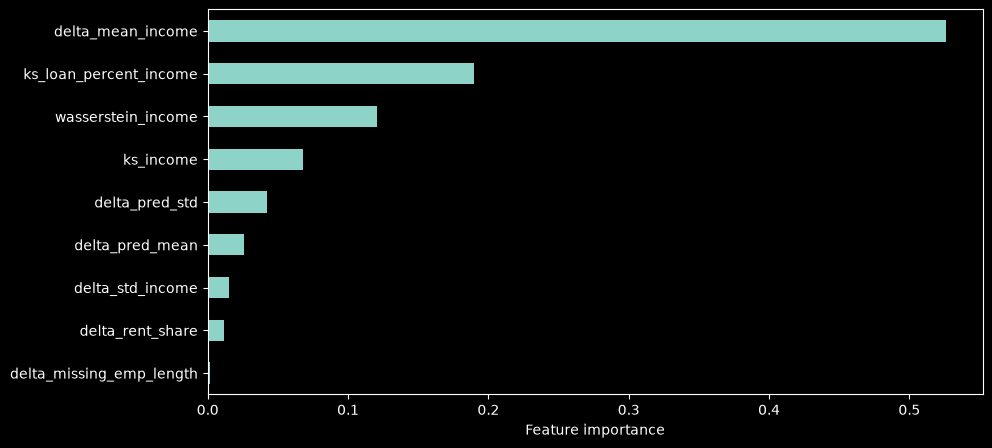

In [83]:
import matplotlib.pyplot as plt

importance.sort_values().plot.barh(figsize=(10, 5))
plt.xlabel("Feature importance")
plt.show()

### **Анализ важности мета-признаков**

Наибольшую важность получили `delta_mean_income` (52.6%), `ks_loan_percent_income` (18.9%) и `wasserstein_income` (12.1%).

Таким образом, основную роль в предсказаниях RandomForest играют характеристики изменения распределений исходных признаков.

Важность рассчитана по уменьшению критерия разделения в деревьях и не отражает причинное влияние признаков на качество production-модели.

In [79]:
baseline_pred = np.full(
    len(y_meta_test),
    y_meta.mean()
)

print("Baseline MAE:", mean_absolute_error(y_meta_test, baseline_pred))

Baseline MAE: 0.024174038322605847


#### Насколько меняется ROC-AUC при реальном дрейфе

In [80]:
missing = df_meta_test[
    df_meta_test["scenario"] == "missing_shift"
]

print(missing["delta_auc"].describe())
print("Zero baseline MAE:", missing["delta_auc"].abs().mean())

count    300.000000
mean      -0.000508
std        0.001145
min       -0.004740
25%       -0.001083
50%       -0.000399
75%        0.000141
max        0.004280
Name: delta_auc, dtype: float64
Zero baseline MAE: 0.0008968723591646669


In [81]:
df_meta_test.groupby("scenario")["delta_auc"].apply(
    lambda x: x.abs().mean()
)

scenario
categorical_shift    0.010448
combined_shift       0.023145
mean_shift           0.056433
missing_noise        0.037739
missing_shift        0.000897
noise_shift          0.037591
population_shift     0.009433
variance_shift       0.048900
Name: delta_auc, dtype: float64

### **Проверка основной гипотезы DriftImpact**

Основная гипотеза проекта заключается в том, что статистическая сила дрейфа не всегда соответствует величине изменения качества production-модели.

В эксперименте `missing_shift` увеличение доли пропусков почти на 30 процентных пунктов сопровождалось средним абсолютным изменением ROC-AUC всего на 0.00139.

В то же время при слабом `mean_shift` средняя просадка ROC-AUC составила около 0.0499.

Полученные результаты иллюстрируют, что влияние дрейфа на качество зависит от характера изменений и затронутых признаков, а не только от величины статистического отклонения.

In [84]:
missing = df_meta_test[
    df_meta_test["scenario"] == "missing_shift"
]

missing.groupby("intensity").agg(
    missing_change=("delta_missing_emp_length", "mean"),
    auc_change=("delta_auc", lambda x: x.abs().mean())
)

,missing_change,auc_change
intensity,,
average,0.149873,0.000867
high,0.299940,0.001392
low,0.050287,0.000431


In [85]:
df_meta_test[
    df_meta_test["scenario"] == "mean_shift"
].groupby("intensity").agg(
    ks_income=("ks_income", "mean"),
    delta_auc=("delta_auc", "mean"),
    abs_delta_auc=("delta_auc", lambda x: x.abs().mean())
)

,ks_income,delta_auc,abs_delta_auc
intensity,,,
average,0.488707,-0.056531,0.056531
high,0.752293,-0.062875,0.062875
low,0.272693,-0.049893,0.049893


### **Сравнение реального и предсказанного ΔROC-AUC**

График отображает соответствие между фактическим изменением качества production-модели и прогнозом DriftImpact.

Диагональная линия соответствует идеальному предсказанию. Отклонения точек от диагонали характеризуют ошибки метамодели.

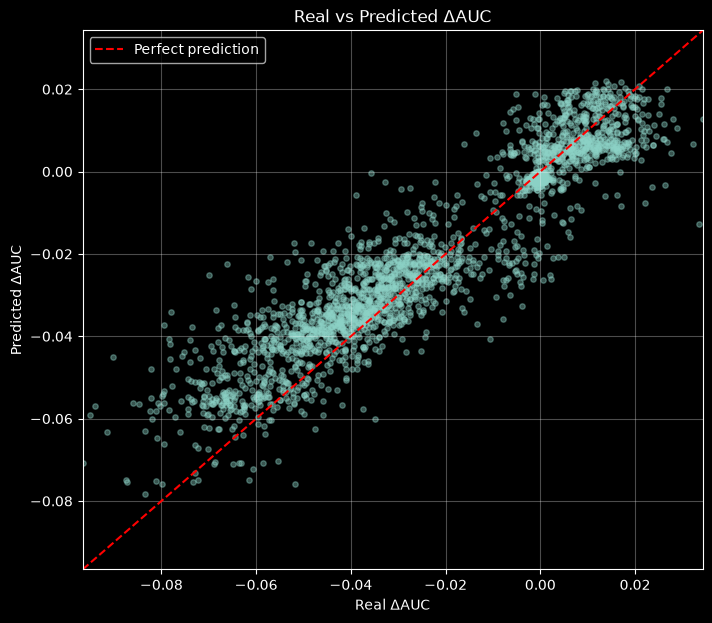

In [87]:
import matplotlib.pyplot as plt
import numpy as np

real = y_meta_test.to_numpy()
pred = y_pred_test

min_val = min(real.min(), pred.min())
max_val = max(real.max(), pred.max())

plt.figure(figsize=(8, 7))

plt.scatter(real, pred, alpha=0.4, s=15)

# Линия идеального предсказания
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    label='Perfect prediction'
)

plt.xlabel('Real ΔAUC')
plt.ylabel('Predicted ΔAUC')
plt.title('Real vs Predicted ΔAUC')

plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [89]:
mask = y_meta_test < -0.05

print("Количество:", mask.sum())
print("MAE:", mean_absolute_error(y_meta_test[mask], y_pred_test[mask]))
print("Среднее смещение:", (y_pred_test[mask] - y_meta_test[mask].to_numpy()).mean())

Количество: 432
MAE: 0.014175897057724176
Среднее смещение: 0.013414803794138222


### **Анализ критических просадок качества**

Дополнительно оценивается способность DriftImpact обнаруживать сценарии с падением ROC-AUC более чем на 0.05.

При заданном пороге получены Precision = 0.897 и Recall = 0.484.

Модель достаточно точно определяет критические просадки среди сформированных предупреждений, однако пропускает значительную долю действительно критических случаев.

In [90]:
from sklearn.metrics import precision_score, recall_score

critical_real = y_meta_test < -0.05
critical_pred = y_pred_test < -0.05

print("Precision:", precision_score(critical_real, critical_pred))
print("Recall:", recall_score(critical_real, critical_pred))

Precision: 0.8969957081545065
Recall: 0.4837962962962963


### **Гистрограмма распределения ошибок**

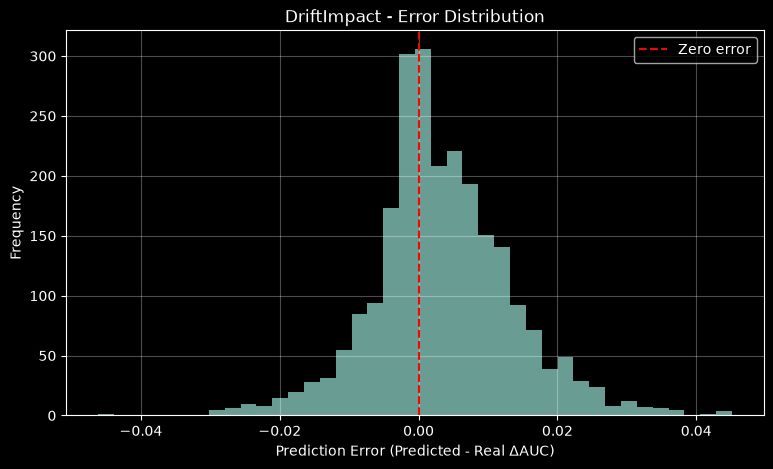

In [91]:
errors = y_pred_test - y_meta_test.to_numpy()

plt.figure(figsize=(9, 5))

plt.hist(errors, bins=40, alpha=0.75)

plt.axvline(0, color='red', linestyle='--', label='Zero error')

plt.xlabel('Prediction Error (Predicted - Real ΔAUC)')
plt.ylabel('Frequency')
plt.title('DriftImpact - Error Distribution')

plt.grid(alpha=0.3)
plt.legend()
plt.show()

## **Итоговые выводы**

В рамках проекта DriftImpact реализован и экспериментально проверен подход к прогнозированию изменения ROC-AUC production-модели без использования актуальных целевых значений на этапе предсказания.

На независимой выборке синтетических сценариев итоговая метамодель RandomForestRegressor достигла MAE = 0.00782 и R² = 0.8443, значительно превзойдя константные baseline.

Эксперименты показали, что величина статистического дрейфа не всегда соответствует степени ухудшения качества модели. При этом обнаружено ограничение в прогнозировании критических просадок.

**Ограничения MVP:** один датасет, одна production-модель, синтетические сценарии с известными механизмами генерации и ограниченный набор мета-признаков.

Дальнейшее развитие предполагает проверку на новых датасетах, неизвестных типах дрейфа и естественных временных изменениях данных.